# LDI-NET: Plant Disease Detection — Kaggle Reproduction

**Paper:** *A novel plant type, leaf disease and severity identification framework using CNN and transformer with multilabel method* (Yang et al., Scientific Reports, 2024, DOI: 10.1038/s41598-024-62452-x)

**Framework:** PyTorch | **Architecture:** Hybrid CNN + Transformer (Feature Tokenizer + Token Encoder + Classifier Head)

This notebook reproduces **LDI-NET** adapted to a **single-label** plant disease dataset. The original multi-label decoder (12 plant + 19 disease + 3 severity queries) is replaced by a **Global Average Pooling + Linear** classifier head since the target dataset is single-label.

Two scenarios are run:
- **Scenario 1 — Baseline:** training transform = Resize + ToTensor + Normalize only.
- **Scenario 2 — Augmented:** + RandomHorizontalFlip, RandomRotation, RandomResizedCrop, ColorJitter.


In [1]:
# Install dependency for model summary
!pip install -q torchinfo

In [2]:
# ─── IMPORTS ──────────────────────────────────────────────────────────────────
import os
import gc
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torchinfo import summary
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

print("Torch version:", torch.__version__)

Torch version: 2.10.0+cu128


In [3]:
# ─── REPRODUCIBILITY + DEVICE DETECTION ──────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()
print(f"Device: {device} | GPUs available: {n_gpus}")

# Full GPU reproducibility (Rule 9)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

Device: cuda | GPUs available: 2


In [4]:
# ─── CONFIG (all hyperparameters from implement_plan.md) ──────────────────────
# Architecture
IMG_SIZE      = 224
PATCH_SIZE    = 16
EMBED_DIM     = 384          # confirmed by user
N_HEADS       = 6            # 384 / 6 = 64 per head
N_FTM_BLOCKS  = 2            # transformer blocks inside Feature Tokenizer Module
N_ENC_BLOCKS  = 2            # Token Encoder blocks
MLP_RATIO     = 4            # hidden = 4 * 384 = 1536
DROPOUT       = 0.1
CONV_OUT_CH   = 384          # = EMBED_DIM
NUM_PATCHES   = (IMG_SIZE // PATCH_SIZE) ** 2   # 14*14 = 196

# Training
BATCH_SIZE    = 16
EPOCHS        = 60
LR            = 6.25e-6
WEIGHT_DECAY  = 0.01
STEP_SIZE     = 4
GAMMA         = 0.5

# Normalization (ImageNet)
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD  = [0.229, 0.224, 0.225]

# Dataset (already split into train/val/test)
DATASET_PATH = "/kaggle/input/datasets/nguynthhnghnh123/ot-final/dataset_smartcrop_plit_300"
TRAIN_DIR = os.path.join(DATASET_PATH, "train")
VAL_DIR   = os.path.join(DATASET_PATH, "val")
TEST_DIR  = os.path.join(DATASET_PATH, "test")

# Output artifact paths
WORK_DIR = "/kaggle/working"
print("Config loaded.")

Config loaded.


In [5]:
# ─── CLASS DETECTION (auto-detect, no hard-code) ─────────────────────────────
_probe = datasets.ImageFolder(TRAIN_DIR)
class_names = _probe.classes
NUM_CLASSES = len(class_names)
print(f"Detected {NUM_CLASSES} classes:")
for i, c in enumerate(class_names):
    print(f"  [{i}] {c}")

Detected 5 classes:
  [0] anthracnose
  [1] healthy
  [2] leaf_curl
  [3] leaf_spot
  [4] nutrient_deficiency


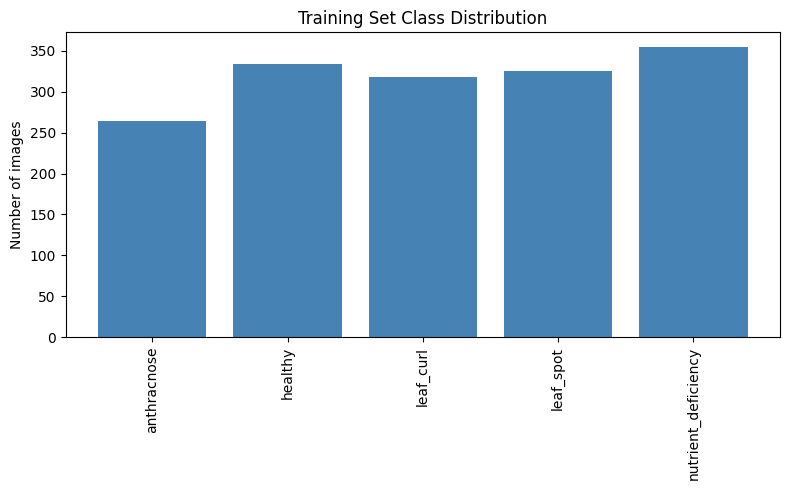

Train images: 1597 | max/min ratio = 1.34
[Class Imbalance] ratio < 1.5 -> NOT using class weights.


In [6]:
# ─── DATASET DISTRIBUTION + CLASS IMBALANCE AUTO-DETECTION (Rule 11) ──────────
train_targets = np.array(_probe.targets)
counts = np.array([(train_targets == i).sum() for i in range(NUM_CLASSES)])

plt.figure(figsize=(max(8, NUM_CLASSES * 0.5), 5))
plt.bar(range(NUM_CLASSES), counts, color="steelblue")
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.ylabel("Number of images")
plt.title("Training Set Class Distribution")
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "class_distribution.png"), dpi=300)
plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f"Train images: {counts.sum()} | max/min ratio = {imbalance_ratio:.2f}")

USE_CLASS_WEIGHTS = imbalance_ratio >= 1.5
if USE_CLASS_WEIGHTS:
    cw = compute_class_weight(class_weight="balanced",
                              classes=np.arange(NUM_CLASSES),
                              y=train_targets)
    class_weights_tensor = torch.tensor(cw, dtype=torch.float32).to(device)
    print(f"[Class Imbalance] ratio >= 1.5 -> USING class weights.")
else:
    class_weights_tensor = None
    print(f"[Class Imbalance] ratio < 1.5 -> NOT using class weights.")

## Model Definition — LDI-NET (single-label adaptation)

In [7]:
# ─── LDI-NET MODEL DEFINITION ────────────────────────────────────────────────

class TransformerBlock(nn.Module):
    """Pre-norm Transformer block: LN -> MHSA -> residual; LN -> MLP -> residual."""
    def __init__(self, dim, n_heads, mlp_ratio, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn  = nn.MultiheadAttention(dim, n_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        h = self.norm1(x)
        attn_out, _ = self.attn(h, h, h)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x


class FeatureTokenizerModule(nn.Module):
    """Module 1: Conv patch-embed -> +PosEmbed -> N TransformerBlocks -> Conv2d(local).
    Returns compact spatial tokens (B, NUM_PATCHES, EMBED_DIM)."""
    def __init__(self, in_ch=3, embed_dim=EMBED_DIM, patch_size=PATCH_SIZE,
                 num_patches=NUM_PATCHES, n_blocks=N_FTM_BLOCKS,
                 n_heads=N_HEADS, mlp_ratio=MLP_RATIO, dropout=DROPOUT,
                 conv_out_ch=CONV_OUT_CH, grid=IMG_SIZE // PATCH_SIZE):
        super().__init__()
        self.grid = grid
        self.embed_dim = embed_dim
        # Patch embedding via strided conv
        self.patch_embed = nn.Conv2d(in_ch, embed_dim,
                                     kernel_size=patch_size, stride=patch_size)
        # Learnable position embedding (1, num_patches, embed_dim)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        # N transformer blocks
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, n_heads, mlp_ratio, dropout)
            for _ in range(n_blocks)
        ])
        # Final conv to capture local information
        self.local_conv = nn.Conv2d(embed_dim, conv_out_ch,
                                    kernel_size=3, padding=1)

    def forward(self, x):
        # x: (B, 3, 224, 224)
        x = self.patch_embed(x)                 # (B, D, 14, 14)
        B, D, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)        # (B, 196, D)
        x = x + self.pos_embed                   # add position embedding
        for blk in self.blocks:
            x = blk(x)                           # (B, 196, D)
        # reshape back to spatial for local conv
        x = x.transpose(1, 2).reshape(B, D, H, W)   # (B, D, 14, 14)
        x = self.local_conv(x)                   # (B, D, 14, 14)
        x = x.flatten(2).transpose(1, 2)        # (B, 196, D) compact spatial tokens
        return x


class TokenEncoderModule(nn.Module):
    """Module 2: 2 Token Encoder blocks producing context-rich tokens.
    Output fused = compact_spatial_tokens + context_rich_tokens (residual add)."""
    def __init__(self, embed_dim=EMBED_DIM, n_blocks=N_ENC_BLOCKS,
                 n_heads=N_HEADS, mlp_ratio=MLP_RATIO, dropout=DROPOUT):
        super().__init__()
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, n_heads, mlp_ratio, dropout)
            for _ in range(n_blocks)
        ])

    def forward(self, compact_tokens):
        x = compact_tokens
        for blk in self.blocks:
            x = blk(x)                           # context-rich tokens
        fused = compact_tokens + x               # residual addition (Fig 1)
        return fused


class ClassifierHead(nn.Module):
    """Module 3 (single-label adaptation): GAP over tokens -> LayerNorm -> Linear."""
    def __init__(self, embed_dim=EMBED_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.norm = nn.LayerNorm(embed_dim)
        self.fc   = nn.Linear(embed_dim, num_classes)

    def forward(self, fused_tokens):
        x = fused_tokens.mean(dim=1)             # GAP over 196 tokens -> (B, D)
        x = self.norm(x)
        return self.fc(x)                         # (B, num_classes)


class LDINET(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.ftm = FeatureTokenizerModule()
        self.encoder = TokenEncoderModule()
        self.head = ClassifierHead(num_classes=num_classes)

    def forward(self, x):
        compact = self.ftm(x)            # (B, 196, 384)
        fused   = self.encoder(compact)  # (B, 196, 384)
        logits  = self.head(fused)       # (B, num_classes)
        return logits

print("LDI-NET model defined.")

LDI-NET model defined.


## Scenario 1: Baseline (no augmentation)

Training transform = Resize + ToTensor + Normalize only. Validation/Test use the same baseline transform.

In [8]:
# ─── TRANSFORMS — Scenario 1 (Baseline) ──────────────────────────────────────
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

# Baseline training transform == eval transform (no augmentation)
train_transform_s1 = eval_transform
print("Scenario 1 transforms ready (baseline = Resize + ToTensor + Normalize).")

Scenario 1 transforms ready (baseline = Resize + ToTensor + Normalize).


In [9]:
# ─── DATALOADERS — Scenario 1 ────────────────────────────────────────────────
train_ds_s1 = datasets.ImageFolder(TRAIN_DIR, transform=train_transform_s1)
val_ds_s1   = datasets.ImageFolder(VAL_DIR,   transform=eval_transform)
test_ds_s1  = datasets.ImageFolder(TEST_DIR,  transform=eval_transform)

train_loader_s1 = DataLoader(train_ds_s1, batch_size=BATCH_SIZE, shuffle=True,
                             num_workers=4, pin_memory=True)
val_loader_s1   = DataLoader(val_ds_s1, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=4, pin_memory=True)
test_loader_s1  = DataLoader(test_ds_s1, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=4, pin_memory=True)

print(f"Train: {len(train_ds_s1)} | Val: {len(val_ds_s1)} | Test: {len(test_ds_s1)}")

Train: 1597 | Val: 491 | Test: 373


In [10]:
# ─── SHARED TRAIN / EVAL HELPERS ─────────────────────────────────────────────

def build_criterion():
    if USE_CLASS_WEIGHTS:
        return nn.CrossEntropyLoss(weight=class_weights_tensor)
    return nn.CrossEntropyLoss()


def run_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train_mode):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            if train_mode:
                optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            if train_mode:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, ckpt_path, tag=""):
    criterion = build_criterion()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0

    for epoch in range(EPOCHS):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion, optimizer=None)
        scheduler.step()

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            _state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
            torch.save(_state, ckpt_path)
            flag = "  <- best saved"
        else:
            flag = ""
        print(f"[{tag}] Epoch {epoch+1:02d}/{EPOCHS} | "
              f"train_loss={tr_loss:.4f} acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} acc={va_acc:.4f} | "
              f"{time.time()-t0:.1f}s{flag}")

    print(f"[{tag}] Best val acc: {best_val_acc:.4f}")
    return history


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        all_preds.append(outputs.argmax(1).cpu().numpy())
        all_labels.append(labels.numpy())
    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="macro", zero_division=0)
    rec = recall_score(labels, preds, average="macro", zero_division=0)
    return preds, labels, acc, f1, rec


def count_params(model):
    m = model.module if isinstance(model, nn.DataParallel) else model
    return sum(p.numel() for p in m.parameters())


def plot_learning_curve(history, title, save_path):
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(epochs_range, history["train_loss"], label="Train Loss")
    ax[0].plot(epochs_range, history["val_loss"], label="Val Loss")
    ax[0].set_title(f"{title} — Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
    ax[1].plot(epochs_range, history["train_acc"], label="Train Acc")
    ax[1].plot(epochs_range, history["val_acc"], label="Val Acc")
    ax[1].set_title(f"{title} — Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()


def plot_confusion_matrix(labels, preds, title, save_path):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(max(7, NUM_CLASSES * 0.6), max(6, NUM_CLASSES * 0.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.xticks(rotation=90); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

print("Helpers ready.")

Helpers ready.


In [11]:
# ─── MODEL INSTANTIATION + SUMMARY — Scenario 1 ──────────────────────────────
model_s1 = LDINET(num_classes=NUM_CLASSES).to(device)
if n_gpus > 1:
    model_s1 = nn.DataParallel(model_s1)
    print(f"[Multi-GPU] DataParallel on {n_gpus} GPUs")

_m = model_s1.module if isinstance(model_s1, nn.DataParallel) else model_s1
summary(_m, input_size=(1, 3, IMG_SIZE, IMG_SIZE))

[Multi-GPU] DataParallel on 2 GPUs


Layer (type:depth-idx)                        Output Shape              Param #
LDINET                                        [1, 5]                    --
├─FeatureTokenizerModule: 1-1                 [1, 196, 384]             75,264
│    └─Conv2d: 2-1                            [1, 384, 14, 14]          295,296
│    └─ModuleList: 2-2                        --                        --
│    │    └─TransformerBlock: 3-1             [1, 196, 384]             1,774,464
│    │    └─TransformerBlock: 3-2             [1, 196, 384]             1,774,464
│    └─Conv2d: 2-3                            [1, 384, 14, 14]          1,327,488
├─TokenEncoderModule: 1-2                     [1, 196, 384]             --
│    └─ModuleList: 2-4                        --                        --
│    │    └─TransformerBlock: 3-3             [1, 196, 384]             1,774,464
│    │    └─TransformerBlock: 3-4             [1, 196, 384]             1,774,464
├─ClassifierHead: 1-3                         [1, 5

In [12]:
# ─── TRAINING — Scenario 1 (Baseline) ────────────────────────────────────────
CKPT_S1 = os.path.join(WORK_DIR, "best_model_s1.pth")
history_s1 = train_model(model_s1, train_loader_s1, val_loader_s1, CKPT_S1, tag="S1")

[S1] Epoch 01/60 | train_loss=1.0610 acc=0.5642 | val_loss=0.9256 acc=0.6130 | 243.8s  <- best saved
[S1] Epoch 02/60 | train_loss=0.8373 acc=0.6550 | val_loss=0.8103 acc=0.6741 | 237.1s  <- best saved
[S1] Epoch 03/60 | train_loss=0.7891 acc=0.6700 | val_loss=0.8061 acc=0.6558 | 235.9s
[S1] Epoch 04/60 | train_loss=0.7406 acc=0.6882 | val_loss=0.7403 acc=0.7149 | 240.2s  <- best saved
[S1] Epoch 05/60 | train_loss=0.6939 acc=0.7163 | val_loss=0.7071 acc=0.7210 | 236.9s  <- best saved
[S1] Epoch 06/60 | train_loss=0.6794 acc=0.7220 | val_loss=0.7197 acc=0.7169 | 238.3s
[S1] Epoch 07/60 | train_loss=0.6647 acc=0.7332 | val_loss=0.6692 acc=0.7271 | 238.1s  <- best saved
[S1] Epoch 08/60 | train_loss=0.6398 acc=0.7439 | val_loss=0.6669 acc=0.7413 | 238.2s  <- best saved
[S1] Epoch 09/60 | train_loss=0.6119 acc=0.7545 | val_loss=0.6323 acc=0.7434 | 238.4s  <- best saved
[S1] Epoch 10/60 | train_loss=0.6033 acc=0.7671 | val_loss=0.6281 acc=0.7413 | 235.8s
[S1] Epoch 11/60 | train_loss=0.591

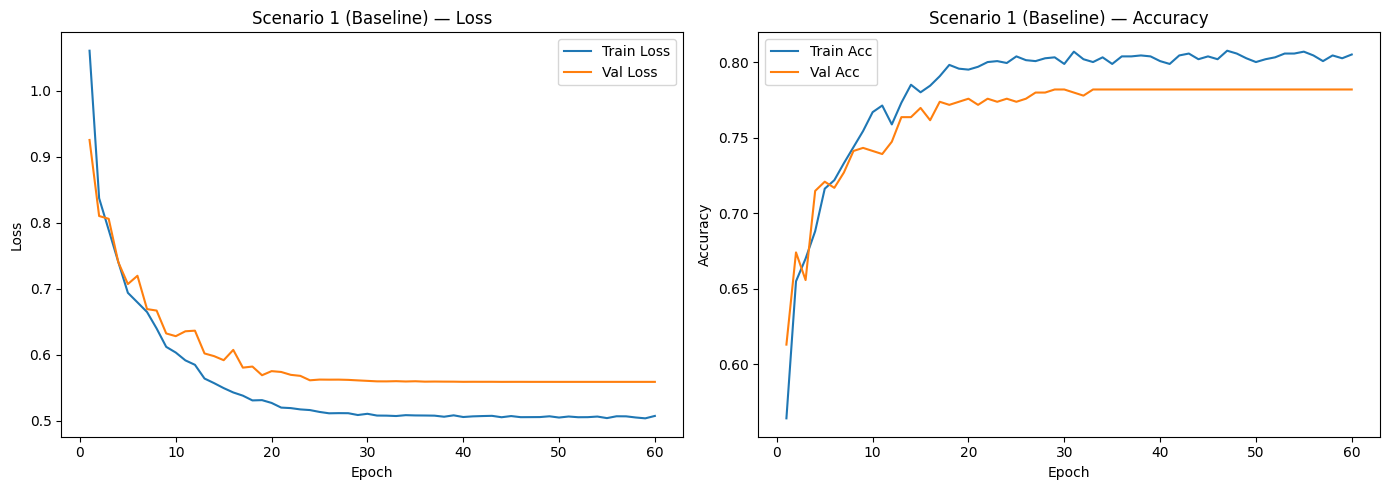

In [13]:
# ─── LEARNING CURVE — Scenario 1 ─────────────────────────────────────────────
BASELINE_LEARNING_CURVE_PATH = os.path.join(WORK_DIR, "learning_curve_s1.png")
plot_learning_curve(history_s1, "Scenario 1 (Baseline)", BASELINE_LEARNING_CURVE_PATH)

In [14]:
# ─── EVALUATION — Scenario 1 (reload best checkpoint) ────────────────────────
_target = model_s1.module if isinstance(model_s1, nn.DataParallel) else model_s1
_target.load_state_dict(torch.load(CKPT_S1, map_location=device))

preds_s1, labels_s1, acc_s1, f1_s1, rec_s1 = evaluate(model_s1, test_loader_s1)
print(f"[S1] Test Accuracy : {acc_s1:.4f}")
print(f"[S1] F1 (macro)    : {f1_s1:.4f}")
print(f"[S1] Recall (macro): {rec_s1:.4f}\n")
print("Classification Report (Scenario 1):")
print(classification_report(labels_s1, preds_s1, target_names=class_names, zero_division=0))

baseline_metrics = {
    "model_name": "LDI-NET",
    "accuracy": acc_s1,
    "f1_macro": f1_s1,
    "recall_macro": rec_s1,
    "total_params": count_params(model_s1),
}

[S1] Test Accuracy : 0.7694
[S1] F1 (macro)    : 0.7660
[S1] Recall (macro): 0.7765

Classification Report (Scenario 1):
                     precision    recall  f1-score   support

        anthracnose       1.00      0.98      0.99        62
            healthy       0.62      0.92      0.74        78
          leaf_curl       0.72      0.81      0.76        74
          leaf_spot       0.76      0.38      0.51        76
nutrient_deficiency       0.87      0.78      0.82        83

           accuracy                           0.77       373
          macro avg       0.79      0.78      0.77       373
       weighted avg       0.79      0.77      0.76       373



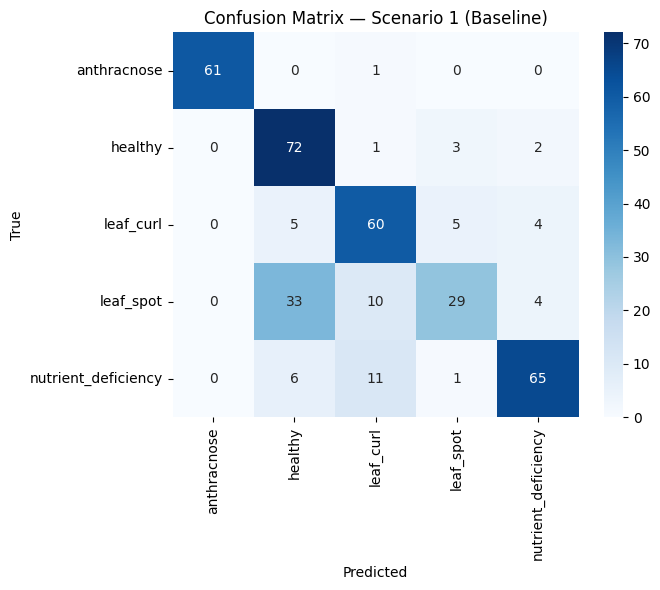

In [15]:
# ─── CONFUSION MATRIX — Scenario 1 ───────────────────────────────────────────
BASELINE_CONFUSION_MATRIX_PATH = os.path.join(WORK_DIR, "confusion_matrix_s1.png")
plot_confusion_matrix(labels_s1, preds_s1, "Confusion Matrix — Scenario 1 (Baseline)",
                      BASELINE_CONFUSION_MATRIX_PATH)

In [16]:
# ─── MEMORY CLEANUP between scenarios (Rule 13) ──────────────────────────────
del model_s1, train_loader_s1, val_loader_s1, test_loader_s1
gc.collect()
torch.cuda.empty_cache()
print("Cleared GPU memory before Scenario 2.")

Cleared GPU memory before Scenario 2.


## Scenario 2: Augmented

Training transform adds 4 augmentations: RandomHorizontalFlip, RandomRotation(15), RandomResizedCrop, ColorJitter. Validation/Test transforms remain baseline (no augmentation).

In [17]:
# ─── TRANSFORMS — Scenario 2 (Augmented) ─────────────────────────────────────
train_transform_s2 = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),   # Zoom/Scale
    transforms.RandomHorizontalFlip(),                          # Horizontal Flip
    transforms.RandomRotation(15),                              # Rotation
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),  # ColorJitter
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])
# eval_transform reused for val/test (no augmentation)
print("Scenario 2 transforms ready (4 augmentations on training set).")

Scenario 2 transforms ready (4 augmentations on training set).


In [18]:
# ─── DATALOADERS — Scenario 2 ────────────────────────────────────────────────
train_ds_s2 = datasets.ImageFolder(TRAIN_DIR, transform=train_transform_s2)
val_ds_s2   = datasets.ImageFolder(VAL_DIR,   transform=eval_transform)
test_ds_s2  = datasets.ImageFolder(TEST_DIR,  transform=eval_transform)

train_loader_s2 = DataLoader(train_ds_s2, batch_size=BATCH_SIZE, shuffle=True,
                             num_workers=4, pin_memory=True)
val_loader_s2   = DataLoader(val_ds_s2, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=4, pin_memory=True)
test_loader_s2  = DataLoader(test_ds_s2, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=4, pin_memory=True)

print(f"Train: {len(train_ds_s2)} | Val: {len(val_ds_s2)} | Test: {len(test_ds_s2)}")

Train: 1597 | Val: 491 | Test: 373


In [19]:
# ─── MODEL INSTANTIATION (fresh) + SUMMARY — Scenario 2 ──────────────────────
model_s2 = LDINET(num_classes=NUM_CLASSES).to(device)
if n_gpus > 1:
    model_s2 = nn.DataParallel(model_s2)
    print(f"[Multi-GPU] DataParallel on {n_gpus} GPUs")

_m2 = model_s2.module if isinstance(model_s2, nn.DataParallel) else model_s2
summary(_m2, input_size=(1, 3, IMG_SIZE, IMG_SIZE))

[Multi-GPU] DataParallel on 2 GPUs


Layer (type:depth-idx)                        Output Shape              Param #
LDINET                                        [1, 5]                    --
├─FeatureTokenizerModule: 1-1                 [1, 196, 384]             75,264
│    └─Conv2d: 2-1                            [1, 384, 14, 14]          295,296
│    └─ModuleList: 2-2                        --                        --
│    │    └─TransformerBlock: 3-1             [1, 196, 384]             1,774,464
│    │    └─TransformerBlock: 3-2             [1, 196, 384]             1,774,464
│    └─Conv2d: 2-3                            [1, 384, 14, 14]          1,327,488
├─TokenEncoderModule: 1-2                     [1, 196, 384]             --
│    └─ModuleList: 2-4                        --                        --
│    │    └─TransformerBlock: 3-3             [1, 196, 384]             1,774,464
│    │    └─TransformerBlock: 3-4             [1, 196, 384]             1,774,464
├─ClassifierHead: 1-3                         [1, 5

In [20]:
# ─── TRAINING — Scenario 2 (Augmented) ───────────────────────────────────────
CKPT_S2 = os.path.join(WORK_DIR, "best_model_s2.pth")
history_s2 = train_model(model_s2, train_loader_s2, val_loader_s2, CKPT_S2, tag="S2")

[S2] Epoch 01/60 | train_loss=1.1367 acc=0.5304 | val_loss=1.0205 acc=0.5764 | 231.2s  <- best saved
[S2] Epoch 02/60 | train_loss=0.9422 acc=0.6124 | val_loss=0.9023 acc=0.6130 | 234.7s  <- best saved
[S2] Epoch 03/60 | train_loss=0.8705 acc=0.6487 | val_loss=0.9009 acc=0.5927 | 235.9s
[S2] Epoch 04/60 | train_loss=0.8574 acc=0.6487 | val_loss=0.8202 acc=0.6721 | 234.7s  <- best saved
[S2] Epoch 05/60 | train_loss=0.8137 acc=0.6606 | val_loss=0.7943 acc=0.6640 | 232.3s
[S2] Epoch 06/60 | train_loss=0.7886 acc=0.6700 | val_loss=0.7949 acc=0.6354 | 230.6s
[S2] Epoch 07/60 | train_loss=0.7918 acc=0.6700 | val_loss=0.8132 acc=0.6558 | 234.3s
[S2] Epoch 08/60 | train_loss=0.7736 acc=0.6819 | val_loss=0.8119 acc=0.6375 | 240.1s
[S2] Epoch 09/60 | train_loss=0.7429 acc=0.6957 | val_loss=0.7841 acc=0.6721 | 241.5s
[S2] Epoch 10/60 | train_loss=0.7491 acc=0.6888 | val_loss=0.7557 acc=0.6741 | 238.4s  <- best saved
[S2] Epoch 11/60 | train_loss=0.7285 acc=0.7001 | val_loss=0.7781 acc=0.6721 | 2

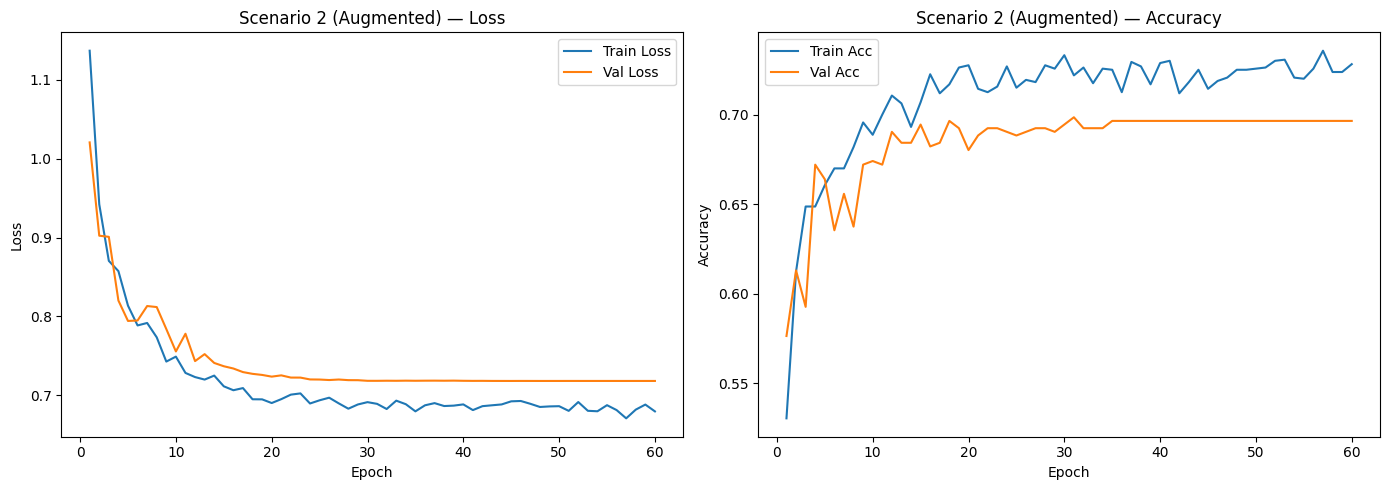

In [21]:
# ─── LEARNING CURVE — Scenario 2 ─────────────────────────────────────────────
AUG_LEARNING_CURVE_PATH = os.path.join(WORK_DIR, "learning_curve_s2.png")
plot_learning_curve(history_s2, "Scenario 2 (Augmented)", AUG_LEARNING_CURVE_PATH)

In [22]:
# ─── EVALUATION — Scenario 2 (reload best checkpoint) ────────────────────────
_target2 = model_s2.module if isinstance(model_s2, nn.DataParallel) else model_s2
_target2.load_state_dict(torch.load(CKPT_S2, map_location=device))

preds_s2, labels_s2, acc_s2, f1_s2, rec_s2 = evaluate(model_s2, test_loader_s2)
print(f"[S2] Test Accuracy : {acc_s2:.4f}")
print(f"[S2] F1 (macro)    : {f1_s2:.4f}")
print(f"[S2] Recall (macro): {rec_s2:.4f}\n")
print("Classification Report (Scenario 2):")
print(classification_report(labels_s2, preds_s2, target_names=class_names, zero_division=0))

aug_metrics = {
    "model_name": "LDI-NET",
    "accuracy": acc_s2,
    "f1_macro": f1_s2,
    "recall_macro": rec_s2,
    "total_params": count_params(model_s2),
}

[S2] Test Accuracy : 0.7158
[S2] F1 (macro)    : 0.7167
[S2] Recall (macro): 0.7234

Classification Report (Scenario 2):
                     precision    recall  f1-score   support

        anthracnose       0.98      0.97      0.98        62
            healthy       0.60      0.78      0.68        78
          leaf_curl       0.58      0.70      0.63        74
          leaf_spot       0.74      0.38      0.50        76
nutrient_deficiency       0.79      0.78      0.79        83

           accuracy                           0.72       373
          macro avg       0.74      0.72      0.72       373
       weighted avg       0.73      0.72      0.71       373



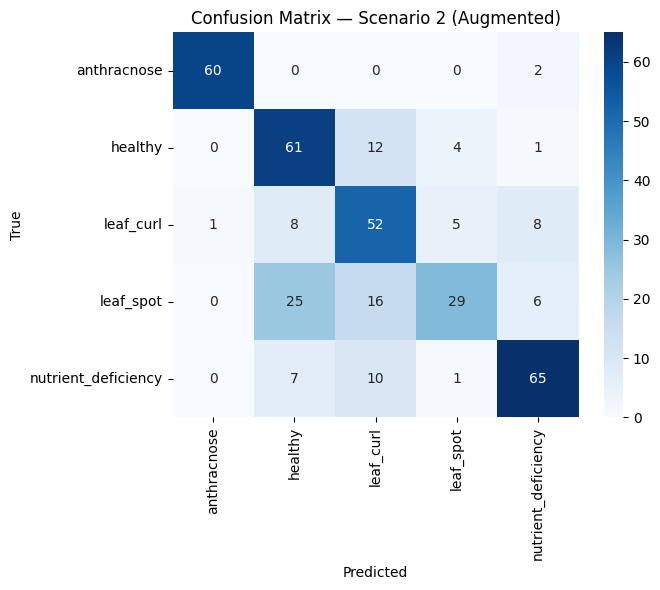

In [23]:
# ─── CONFUSION MATRIX — Scenario 2 ───────────────────────────────────────────
AUG_CONFUSION_MATRIX_PATH = os.path.join(WORK_DIR, "confusion_matrix_s2.png")
plot_confusion_matrix(labels_s2, preds_s2, "Confusion Matrix — Scenario 2 (Augmented)",
                      AUG_CONFUSION_MATRIX_PATH)

## Summary Comparison: Scenario 1 vs Scenario 2

In [24]:
# ─── SUMMARY COMPARISON TABLE ────────────────────────────────────────────────
print(f"{'Metric':<18}{'Baseline (S1)':<18}{'Augmented (S2)':<18}")
print("-" * 54)
print(f"{'Accuracy':<18}{baseline_metrics['accuracy']:<18.4f}{aug_metrics['accuracy']:<18.4f}")
print(f"{'F1 (macro)':<18}{baseline_metrics['f1_macro']:<18.4f}{aug_metrics['f1_macro']:<18.4f}")
print(f"{'Recall (macro)':<18}{baseline_metrics['recall_macro']:<18.4f}{aug_metrics['recall_macro']:<18.4f}")
print(f"{'Parameters':<18}{baseline_metrics['total_params']:<18,}{aug_metrics['total_params']:<18,}")

Metric            Baseline (S1)     Augmented (S2)    
------------------------------------------------------
Accuracy          0.7694            0.7158            
F1 (macro)        0.7660            0.7167            
Recall (macro)    0.7765            0.7234            
Parameters        8,798,597         8,798,597         


## Export Results to Excel

In [25]:
# ── Install Excel dependencies ───────────────────────────────────────────────
!pip install -q openpyxl Pillow

In [26]:
# ── Export results_summary.xlsx ──────────────────────────────────────────────
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

EXCEL_OUTPUT_PATH = os.path.join(WORK_DIR, "results_summary.xlsx")
MODEL_NAME        = "LDI-NET"

HEADERS = ["STT", "Tên Model", "Accuracy", "F1-score", "Recall",
           "Learning Curve", "Confusion Matrix", "Parameters"]
COL_WIDTHS = [6, 35, 12, 12, 12, 38, 38, 18]
IMG_ROW_HEIGHT = 200

def style_header_row(ws):
    fill = PatternFill("solid", fgColor="1F4E79")
    font = Font(bold=True, color="FFFFFF", size=11)
    border = Border(bottom=Side(style="medium", color="FFFFFF"),
                    right=Side(style="thin", color="FFFFFF"))
    for col, header in enumerate(HEADERS, start=1):
        cell = ws.cell(row=1, column=col, value=header)
        cell.fill, cell.font, cell.border = fill, font, border
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

def write_result_row(ws, row_num, stt, metrics, lc_path, cm_path):
    data = [stt, metrics["model_name"], round(metrics["accuracy"], 4),
            round(metrics["f1_macro"], 4), round(metrics["recall_macro"], 4),
            "", "", f"{metrics['total_params']:,}"]
    for col, val in enumerate(data, start=1):
        cell = ws.cell(row=row_num, column=col, value=val)
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.row_dimensions[row_num].height = IMG_ROW_HEIGHT
    if os.path.exists(lc_path):
        img_lc = XLImage(lc_path); img_lc.width, img_lc.height = 280, 190
        ws.add_image(img_lc, f"F{row_num}")
    if os.path.exists(cm_path):
        img_cm = XLImage(cm_path); img_cm.width, img_cm.height = 280, 190
        ws.add_image(img_cm, f"G{row_num}")

def build_sheet(wb, sheet_name, metrics, lc_path, cm_path):
    ws = wb.create_sheet(title=sheet_name)
    for col, width in enumerate(COL_WIDTHS, start=1):
        ws.column_dimensions[get_column_letter(col)].width = width
    ws.row_dimensions[1].height = 30
    style_header_row(ws)
    write_result_row(ws, 2, 1, metrics, lc_path, cm_path)
    return ws

wb = Workbook()
wb.remove(wb.active)
build_sheet(wb, "Baseline", baseline_metrics,
            BASELINE_LEARNING_CURVE_PATH, BASELINE_CONFUSION_MATRIX_PATH)
build_sheet(wb, "Augmented", aug_metrics,
            AUG_LEARNING_CURVE_PATH, AUG_CONFUSION_MATRIX_PATH)
wb.save(EXCEL_OUTPUT_PATH)
print(f"[Excel] Saved: {EXCEL_OUTPUT_PATH}")
print(f"  Baseline  -> Acc={baseline_metrics['accuracy']:.4f} | F1={baseline_metrics['f1_macro']:.4f} | Recall={baseline_metrics['recall_macro']:.4f} | Params={baseline_metrics['total_params']:,}")
print(f"  Augmented -> Acc={aug_metrics['accuracy']:.4f} | F1={aug_metrics['f1_macro']:.4f} | Recall={aug_metrics['recall_macro']:.4f} | Params={aug_metrics['total_params']:,}")

[Excel] Saved: /kaggle/working/results_summary.xlsx
  Baseline  -> Acc=0.7694 | F1=0.7660 | Recall=0.7765 | Params=8,798,597
  Augmented -> Acc=0.7158 | F1=0.7167 | Recall=0.7234 | Params=8,798,597
